Shopify Stock Market EdA (30. 10. 2026)

In [139]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [100]:
df = pd.read_csv(r"C:\Users\Admin\Desktop\wekaytask\SHOP_2015-05-21_2025-03-16.csv.xls")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [101]:
df.head()

,date,open,high,low,close,adj_close,volume
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000


In [102]:
df.shape

(2469, 7)

In [103]:
df.columns

Index(['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume'], dtype='object')

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2469 entries, 0 to 2468
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       2469 non-null   object 
 1   open       2469 non-null   float64
 2   high       2469 non-null   float64
 3   low        2469 non-null   float64
 4   close      2469 non-null   float64
 5   adj_close  2469 non-null   float64
 6   volume     2469 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 135.2+ KB


In [105]:
df.isnull()

,date,open,high,low,close,adj_close,volume
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
2464,False,False,False,False,False,False,False
2465,False,False,False,False,False,False,False
2466,False,False,False,False,False,False,False
2467,False,False,False,False,False,False,False


In [106]:
df.describe()

,open,high,low,close,adj_close,volume
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03
mean,48.464345,49.505495,47.347795,48.456613,48.456613,1.657049e+07
std,43.633916,44.470235,42.642546,43.573362,43.573362,1.436909e+07
min,1.939000,1.985000,1.848000,1.933000,1.933000,1.039000e+06
25%,10.479000,10.635000,10.275000,10.450000,10.450000,8.098000e+06
50%,35.640999,36.879002,34.655998,35.874001,35.874001,1.275860e+07
75%,76.080002,77.169998,74.589996,75.800003,75.800003,2.060200e+07
max,171.800003,176.291794,168.509506,169.059998,169.059998,2.089590e+08


In [107]:
df.isnull().sum()

date         0
open         0
high         0
low          0
close        0
adj_close    0
volume       0
dtype: int64

In [108]:
df.duplicated().sum()

np.int64(0)

In [109]:
df.dtypes

date          object
open         float64
high         float64
low          float64
close        float64
adj_close    float64
volume         int64
dtype: object

In [110]:
df["date"] = pd.to_datetime(df["date"])

C:\Users\Admin\AppData\Local\Temp\ipykernel_19020\3228555721.py:1: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df["date"] = pd.to_datetime(df["date"])


In [111]:
df["date"].dtype

dtype('O')

In [112]:
df = df.reset_index(drop=True)

In [113]:
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2015-05-21 00:00:00-04:00
End Date: 2025-03-14 00:00:00-04:00


In [114]:
df["date"].duplicated().sum()

np.int64(0)

In [115]:
df = df.set_index("date")

In [116]:
df.head()

,open,high,low,close,adj_close,volume
date,,,,,,
2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000
2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000
2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000
2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000
2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000


In [117]:
df["daily_price_change"] = df["close"] - df["open"]

In [118]:
df[["open", "close", "daily_price_change"]].head()

,open,close,daily_price_change
date,,,
2015-05-21 00:00:00-04:00,2.800,2.568,-0.232
2015-05-22 00:00:00-04:00,2.607,2.831,0.224
2015-05-26 00:00:00-04:00,2.980,2.965,-0.015
2015-05-27 00:00:00-04:00,3.067,2.750,-0.317
2015-05-28 00:00:00-04:00,2.755,2.745,-0.010


In [119]:
df["daily_return"] = df["close"].pct_change()*100

In [120]:
df[["close", "daily_return"]].head()

,close,daily_return
date,,
2015-05-21 00:00:00-04:00,2.568,NaN
2015-05-22 00:00:00-04:00,2.831,10.241433
2015-05-26 00:00:00-04:00,2.965,4.733303
2015-05-27 00:00:00-04:00,2.750,-7.251262
2015-05-28 00:00:00-04:00,2.745,-0.181822


In [121]:
df["price_range"] = df["high"] - df["low"]

In [122]:
df[["high", "low", "price_range"]].head()

,high,low,price_range
date,,,
2015-05-21 00:00:00-04:00,2.874,2.411,0.463
2015-05-22 00:00:00-04:00,3.110,2.600,0.510
2015-05-26 00:00:00-04:00,3.034,2.908,0.126
2015-05-27 00:00:00-04:00,3.081,2.700,0.381
2015-05-28 00:00:00-04:00,2.774,2.648,0.126


In [123]:
print("Mean Return:", df["daily_return"].mean())
print("Variance:", df["daily_return"].var())
print("Standard Deviation:", df["daily_return"].std())

Mean Return: 0.21480626556944574
Variance: 13.78075206243252
Standard Deviation: 3.712243534903458


In [124]:
df["volume"].describe()

count    2.469000e+03
mean     1.657049e+07
std      1.436909e+07
min      1.039000e+06
25%      8.098000e+06
50%      1.275860e+07
75%      2.060200e+07
max      2.089590e+08
Name: volume, dtype: float64

In [125]:
df.loc[df["volume"].idxmax()]

open                  1.168300e+01
high                  1.169300e+01
low                   1.007500e+01
close                 1.033000e+01
adj_close             1.033000e+01
volume                2.089590e+08
daily_price_change   -1.353000e+00
daily_return         -1.156579e+01
price_range           1.618000e+00
Name: 2017-10-04 00:00:00-04:00, dtype: float64

In [126]:
Q1 = df["daily_return"].quantile(0.25)
Q3 = df["daily_return"].quantile(0.75)

In [127]:
IQR = Q3 - Q1

In [128]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [129]:
return_outliers = df[
    (df["daily_return"] < lower_bound) |
    (df["daily_return"] > upper_bound)
]

In [130]:
return_outliers.shape

(122, 9)

In [131]:
return_outliers[["open", "close", "daily_return"]].head(10)

,open,close,daily_return
date,,,
2015-05-22 00:00:00-04:00,2.6070,2.831,10.241433
2015-05-27 00:00:00-04:00,3.0670,2.750,-7.251262
2015-06-11 00:00:00-04:00,2.8490,3.073,9.359431
2015-06-12 00:00:00-04:00,3.1320,3.363,9.437031
2015-06-18 00:00:00-04:00,3.8420,3.555,-7.973074
2015-06-30 00:00:00-04:00,3.1500,3.395,8.397191
2015-07-01 00:00:00-04:00,3.4030,3.111,-8.365241
2015-07-17 00:00:00-04:00,2.9320,3.227,9.799255
2015-07-30 00:00:00-04:00,3.8655,3.813,11.621782


In [132]:
Q1_volume = df["volume"].quantile(0.25)
Q3_volume = df["volume"].quantile(0.75)

IQR_volume = Q3_volume - Q1_volume

lower_volume = Q1_volume - 1.5 * IQR_volume
upper_volume = Q3_volume + 1.5 * IQR_volume

volume_outliers = df[
    (df["volume"] < lower_volume) |
    (df["volume"] > upper_volume)
]


In [133]:
volume_outliers.shape

(136, 9)

In [134]:
df["absolute_return"] = df["daily_return"].abs()

In [135]:
top_volatility_days = df.sort_values(
    "absolute_return",
    ascending=False
).head(10)

In [136]:
top_volatility_days[
    ["open", "high", "low", "close", "daily_return", "volume"]
]

,open,high,low,close,daily_return,volume
date,,,,,,
2023-05-04 00:00:00-04:00,54.869999,59.820000,53.880001,57.299999,23.838337,88927300
2015-09-17 00:00:00-04:00,2.989000,3.795000,2.985000,3.555000,22.967832,21123000
2023-11-02 00:00:00-04:00,57.639999,60.150002,55.507000,59.700001,22.361139,43602900
2024-11-12 00:00:00-05:00,107.519997,114.510002,106.000000,108.919998,21.035671,63946200
2022-03-18 00:00:00-04:00,64.987999,78.000000,64.730003,78.000000,18.652836,46309000
2024-05-08 00:00:00-04:00,63.669998,64.199997,60.639999,62.730000,-18.585338,58311600
2022-11-10 00:00:00-05:00,33.900002,36.599998,33.450001,36.509998,18.155336,32449100
2024-08-07 00:00:00-04:00,64.500000,67.779999,63.549999,63.889999,17.834744,49976600
2020-03-16 00:00:00-04:00,33.900002,36.200001,32.150002,32.229000,-17.551804,41799000


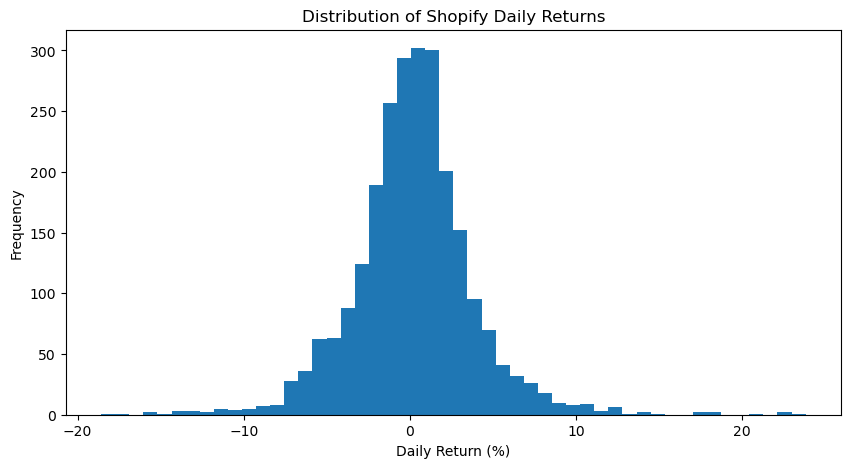

In [140]:
plt.figure(figsize=(10, 5))

plt.hist(df["daily_return"].dropna(), bins=50)

plt.title("Distribution of Shopify Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.show()

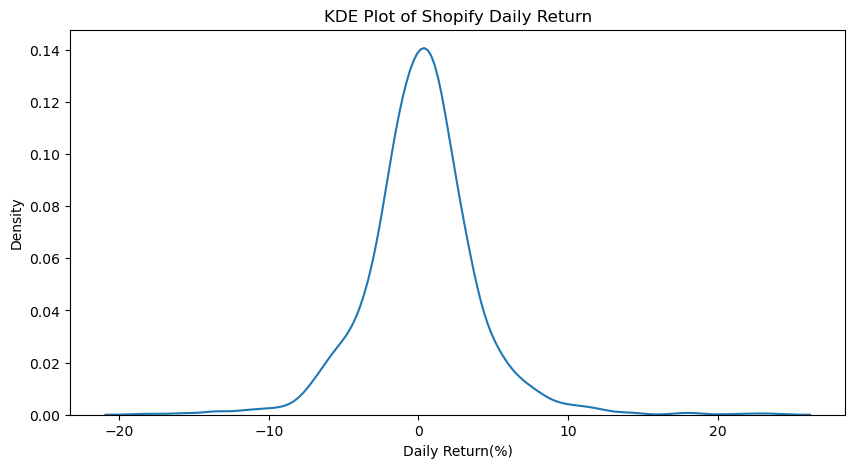

In [141]:
plt.figure(figsize=(10, 5))
sns.kdeplot(df["daily_return"].dropna())
plt.title("KDE Plot of Shopify Daily Return")
plt.xlabel("Daily Return(%)")
plt.ylabel("Density")

plt.show()

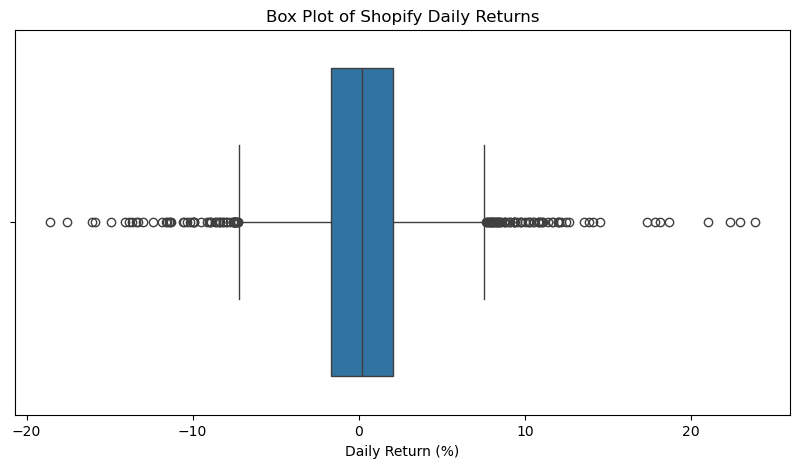

In [142]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["daily_return"].dropna())
plt.title("Box Plot of Shopify Daily Returns")
plt.xlabel("Daily Return (%)")

plt.show()

In [143]:
return_summary = pd.DataFrame({
    "Metric": ["Mean", "Variance", "Standard Deviation"],
    "Value": [
        df["daily_return"].mean(),
        df["daily_return"].var(), 
        df["daily_return"].std()
    ]
})

return_summary

,Metric,Value
0,Mean,0.214806
1,Variance,13.780752
2,Standard Deviation,3.712244


In [144]:
price_summary = df[["open", "high", "low", "close", "volume"]].describe()

price_summary

,open,high,low,close,volume
count,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03
mean,48.464345,49.505495,47.347795,48.456613,1.657049e+07
std,43.633916,44.470235,42.642546,43.573362,1.436909e+07
min,1.939000,1.985000,1.848000,1.933000,1.039000e+06
25%,10.479000,10.635000,10.275000,10.450000,8.098000e+06
50%,35.640999,36.879002,34.655998,35.874001,1.275860e+07
75%,76.080002,77.169998,74.589996,75.800003,2.060200e+07
max,171.800003,176.291794,168.509506,169.059998,2.089590e+08


In [145]:
df.head()

,open,high,low,close,adj_close,volume,daily_price_change,daily_return,price_range,absolute_return
date,,,,,,,,,,
2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,NaN,0.463,NaN
2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,10.241433,0.510,10.241433
2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,4.733303,0.126,4.733303
2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-7.251262,0.381,7.251262
2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.181822,0.126,0.181822


In [146]:
df.columns

Index(['open', 'high', 'low', 'close', 'adj_close', 'volume',
       'daily_price_change', 'daily_return', 'price_range', 'absolute_return'],
      dtype='object')

In [148]:
df.to_csv("shopify_stack_cleaned.csv")

REPORT:

Introduction This project focuses on analysing Shopify stock market data using Python. The analysis covers historical stock prices, trading volume, daily returns, price fluctuations and moving averages.

Stock Price Analysis The Open, High, Low and Close (OHLC) values were analysed to understand Shopify's historical stock price movements.

A time-series line plot was created to visualize changes in stock prices over time.

Trading Volume Analysis Trading volume was analysed using statistical measures such as mean, median, minimum, maximum and standard deviation.
Unusual trading volume records were also identified using the Interquartile Range (IQR) method.

Daily Return Analysis Daily price change and daily return percentage were calculated to understand the daily movement of Shopify stock prices.
The mean, variance and standard deviation were used to study the distribution of daily returns.

Price Volatility Analysis Price volatility was examined using the difference between daily high and low prices.
The days with higher price fluctuations were identified to understand periods of increased market volatility.

Moving Average Analysis The 20-day and 50-day Simple Moving Averages (SMA) were calculated using closing prices.
These moving averages were plotted alongside closing prices to observe historical price trends.

Correlation Analysis Correlation analysis was performed to examine the relationships between trading volume, daily price change and price volatility.
Heatmaps and scatter plots were used to visualize these relationships.

Daily Return Distribution A histogram and Kernel Density Estimation (KDE) plot were created to understand the distribution of daily returns.
These visualizations help examine the spread and shape of stock returns.

Conclusion The Shopify Stock Market Analysis project helped explore historical stock market data using Python.
Data cleaning, feature engineering, statistical analysis and data visualization techniques were applied to understand stock price movements, trading volume, daily returns and market volatility.

The project provided practical experience in Exploratory Data Analysis (EDA) and time-series data visualization.